<a href="https://colab.research.google.com/github/nurilhuda05/Pembelajaran_Mesin_2026/blob/main/TG11_244107020004_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

### **Langkah 1 - Import Library**

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

### **Langkah 2 - Membuat Data Dummy**

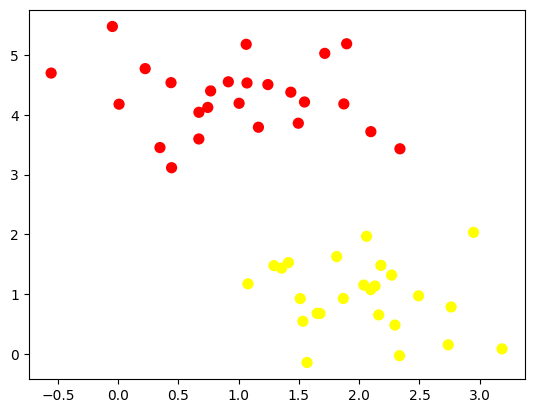

In [24]:
from sklearn.datasets import make_blobs

# Membuat data dengan dua kelas
X, y = make_blobs(
    n_samples=50,
    centers=2,
    random_state=0,
    cluster_std=0.60
)


plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

### **Langkah 3 - Membuat Ilustrasi Garis Pemisah**

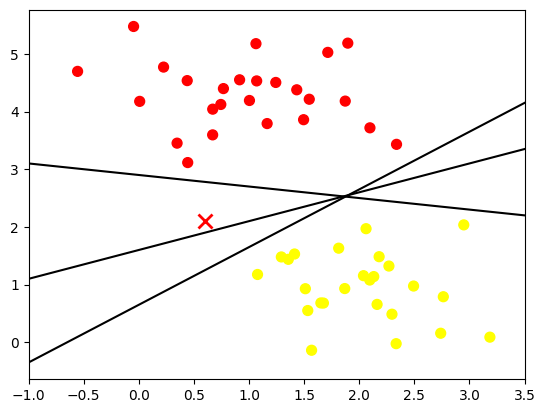

In [25]:
# Rentang sumbu x untuk menggambar garis
xfit = np.linspace(-1, 3.5)

# Plot data dari Langkah 2
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Titik data baru 'x'
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

# Tiga garis pemisah yang berbeda, dengan format (gradien m, intersep b)
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

# Batas sumbu x
plt.xlim(-1, 3.5)
plt.show()

### **Langkah 4 - Ilustrasi Margin**

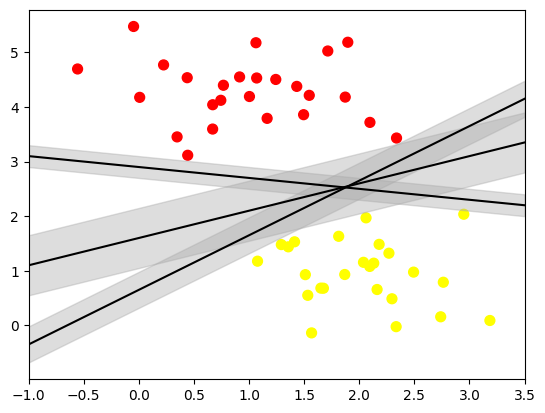

In [26]:
# Membuat rentang nilai untuk garis
xfit = np.linspace(-1, 3.5)

# Menampilkan data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Membuat beberapa garis pemisah dan margin
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(
        xfit,
        yfit - d,
        yfit + d,
        edgecolor='none',
        color='#AAAAAA',
        alpha=0.4
    )

# Mengatur batas sumbu X
plt.xlim(-1, 3.5)
plt.show()

### **Langkah 5 - Fitting Model**

#### **5A - Melatih Model SVM**

In [22]:
# Import algoritma SVM
from sklearn.svm import SVC

# Membuat model SVM dengan kernel linear
model = SVC(kernel='linear', C=1E10)

# Melatih model menggunakan data dummy
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

#### **5B - Membuat fungsi visualisasi garis pemisah**

In [27]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### **5C - Menampilkan hasil model SVM**

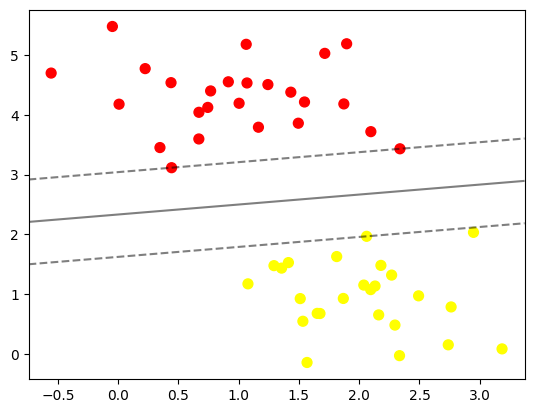

In [29]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

plot_svc_decision_function(model)

plt.show()

#### **5D - Melihat Support Vector**

In [30]:
# Menampilkan titik yang menjadi support vector
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

### **Langkah 6 - Membandingkan Model dengan Jumlah Data Berbeda**

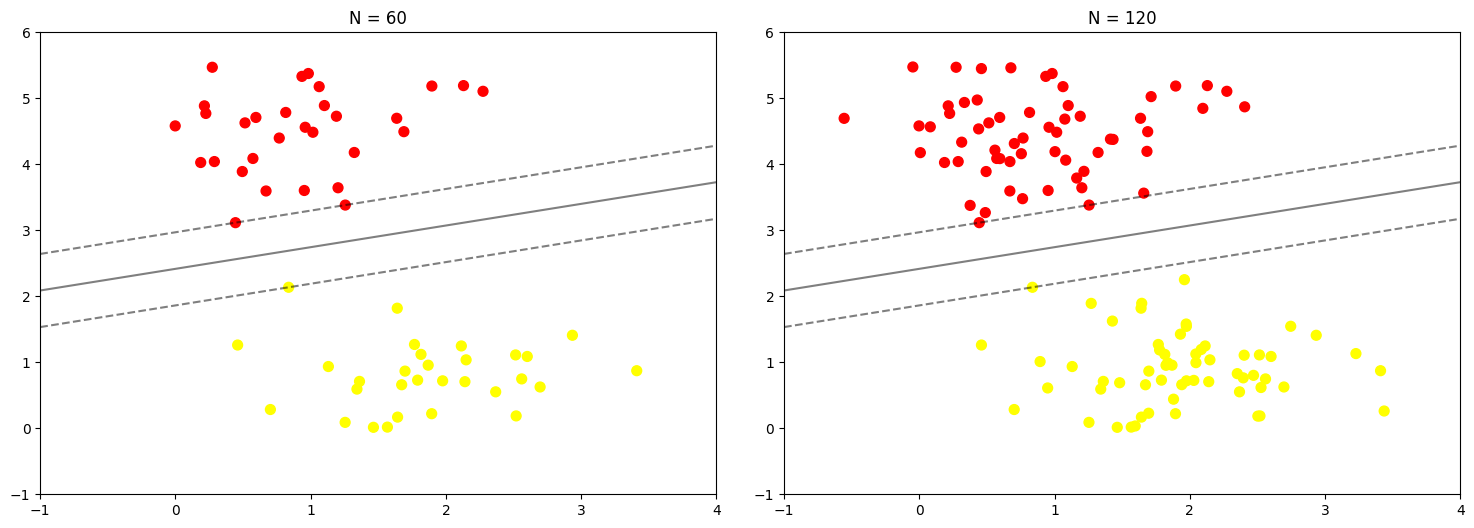

In [31]:
# Fungsi untuk membuat dan menampilkan model SVM
def plot_svm(N=10, ax=None):
    # Membuat 200 data dummy
    X, y = make_blobs(
        n_samples=200,
        centers=2,
        random_state=0,
        cluster_std=0.60
    )

    # Mengambil sejumlah data sesuai N
    X = X[:N]
    y = y[:N]

    # Membuat dan melatih model SVM
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    # Menampilkan data
    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

    # Mengatur batas grafik
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)

    # Menampilkan garis pemisah dan margin
    plot_svc_decision_function(model, ax)


# Membuat dua grafik perbandingan
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Menampilkan model dengan 60 dan 120 data
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {}'.format(N))

plt.show()

### **Langkah 7 - Interaksi Jumlah Data Menggunakan ipywidgets**

#### **7A - Instalasi library**

In [32]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 47.4 MB/s eta 0:00:00


#### **7B - Membuat tampilan interaktif**

In [37]:
# Import library untuk interaksi
from ipywidgets import interact, fixed

# Menampilkan model dengan pilihan jumlah data
interact(plot_svm, N=[10,50,100,150,200], ax=fixed(None))

plt.show()

interactive(children=(Dropdown(description='N', options=(10, 50, 100, 150, 200), value=10), Output()), _dom_cl…

# **PRAKTIKUM 2**

### **Langkah 1 - Ilustrasi Data Non-Linier**

#### **1A - Import Library**

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

#### **1B - Membuat Kembali Fungsi Plotting**

In [39]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### **1C - Membuat Data Dummy Non-Linier**

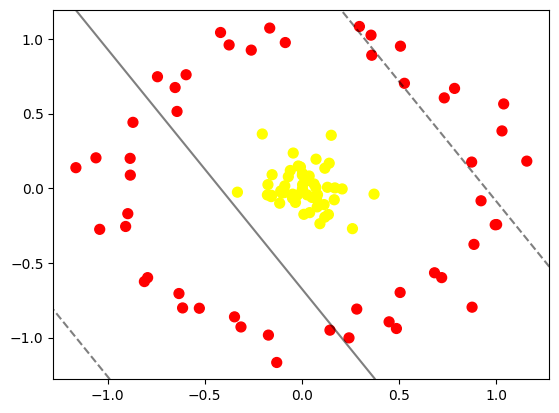

In [44]:
# Import library untuk membuat data lingkaran
from sklearn.datasets import make_circles

# Membuat data dummy non-linier
X, y = make_circles(
    n_samples=100,
    factor=0.1,
    noise=0.1,
    random_state=42
)

# Melatih SVM dengan kernel linear
clf = SVC(kernel='linear')
clf.fit(X, y)

# Menampilkan visualisasi data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menampilkan garis pemisah
plot_svc_decision_function(clf, plot_support=False)

plt.show()

Hasil grafik yang diperoleh berbeda dengan modul karena pada kode ini ditambahkan parameter random_state=42, sedangkan modul tidak menggunakannya. Parameter tersebut membuat data yang dihasilkan tetap sama setiap kali kode dijalankan. Tanpa random_state, data dapat berubah setiap kali dijalankan.

#### **1D - Visualisasi Data dalam Bentuk 3D**

In [58]:
# Import library untuk visualisasi 3D dan interaksi
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# Menghitung proyeksi radial
r = np.exp(-(X**2).sum(1))

# Membuat fungsi visualisasi 3D
def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')

    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')

    ax.view_init(elev=elev, azim=azim)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')


# Menampilkan grafik interaktif
interact(
    plot_3D,
    elev=[-90, 45, 30, 20, 10],
    azim=(-180, 180),
    X=fixed(X),
    y=fixed(y)
)

plt.show()

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

### **Langkah 2 - Fitting Model dengan Kernel RBF**

#### **2A - Melatih model SVM**

In [59]:
# Membuat model SVM dengan kernel RBF
clf = SVC(kernel='rbf', C=1E6)

# Melatih model menggunakan data dummy
clf.fit(X, y)

SVC(C=1000000.0)

#### **2B - Menampilkan hasil klasifikasi**

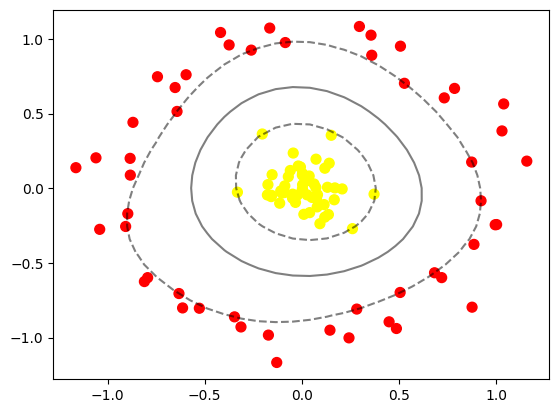

In [60]:
# Menampilkan data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menampilkan garis pemisah dan margin
plot_svc_decision_function(clf)

# Menampilkan support vector
plt.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=300,
    linewidth=1,
    facecolors='none'
)

plt.show()